# A cleaned corpus can teach the wrong lesson

Which useful examples disappear when a corpus looks cleaner, and how would we discover that loss before training a larger model?

This original authored HTML fixture contains eleven training records and four frozen held-out records. Extraction, matching normalization and training text remain separate. The rules are fixed demonstrations, not trained quality classifiers. The reference uses the existing 258-ID byte decoder and `TrainingSession`: three seeds, three arms, 24 updates per arm, 32 valid targets per update. All negative outcomes are retained. No public crawl, pretrained model, external classifier or GPU is used. [Worked notes](06_corpus_curation-solutions.md).

In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(root / "src"))
import copy, json
import numpy as np
import matplotlib.pyplot as plt
from dongxi_llms.corpus_curation_lab import (
    load_fixture, extract_text, matching_text, prepare_corpus, duplicate_audit,
    split_audit, source_exposure, learning_reference, shingles, jaccard)
fixture = load_fixture()
train = [r for r in fixture if r["split"] == "train"]


## Prediction — is extracted text the same as matching text?

Predict what happens to navigation, scripts, accented words, code and visible contact text. Does removing accents for duplicate matching justify removing them from model inputs?

## Checkpoint — trace an actual record

Inspect raw HTML, extracted text and matching text separately. Find an empty extraction. Keep its ID and failure reason in the ledger rather than silently losing it.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

In [2]:
html = '<head><title>hidden</title></head><nav>links</nav><p>Café &amp; code</p><script>noise</script><pre>x &lt; 3</pre>'
visible = extract_text(html)
print("raw HTML:", html, "\ntraining text:", visible, "\nmatching text:", matching_text(visible))
raw = prepare_corpus(train, "raw")
for row in raw["ledger"]:
    if not row["accepted"] or row["slice"] in ("multilingual", "contact"):
        print(row["id"], row["slice"], repr(row["training_text"]), row["reasons"])
assert "Café" in visible and "cafe" in matching_text(visible)

raw HTML: <head><title>hidden</title></head><nav>links</nav><p>Café &amp; code</p><script>noise</script><pre>x &lt; 3</pre> 
training text: Café & code
x < 3 
matching text: cafe code x 3
t08 multilingual 'Vi läser en kort berättelse tillsammans. Sedan frågar vi vem som öppnade dörren och varför barnet väntade utanför huset.\n小猫坐在窗边，看着花园里的雨。' []
t10 contact 'The invented museum contact is guide@example.invalid. The page explains that visitors can ask about the opening hours before planning their visit.' []
t11 noise '' ['no_extracted_content']


### Reference explanation

The standard-library HTML parser removes explicitly named containers; this simple policy is not a production main-content extractor. Matching uses casefold/NFD/punctuation removal while training retains visible accents and punctuation. Contact strings are fictitious; retained contact text shows this pipeline is not a privacy sanitizer. Empty extraction `t11` remains identifiable with its reason code.

## Prediction — which valuable text will a shortness rule remove?

Predict raw, exact-deduplicated and curated retained counts. Identify useful short/code examples likely to fail the eight-word rule.

## Checkpoint — retain the adverse cases

Print removals and compare retention across authored slices. Change only `min_words` from 8 to 3; report which removals persist. This is a rule intervention, not a trained quality estimate.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

raw {'input': 11, 'retained': 10, 'removed': 1} useful removals: []
exact {'input': 11, 'retained': 9, 'removed': 2} useful removals: []
curated {'input': 11, 'retained': 5, 'removed': 6} useful removals: ['t03', 't06', 't07']
t02 story ['normalized_exact_duplicate'] 'The child planted a seed beside the gate. Each morning she carried water to the garden and watched a small green leaf grow.'
t03 story ['verified_near_duplicate'] 'The child planted a seed beside the gate. Each morning she carried water to the garden and watched a tiny green leaf grow.'
t06 short ['short_rule'] 'Drink clean water.'
t07 code ['short_rule', 'repetition_rule'] 'def square(x): return x * x'
t09 noise ['repetition_rule'] 'offer offer offer offer offer offer offer offer offer offer today today'
t11 noise ['no_extracted_content', 'short_rule'] ''
Relaxed rule: {'input': 11, 'retained': 6, 'removed': 5} ['t03', 't07']


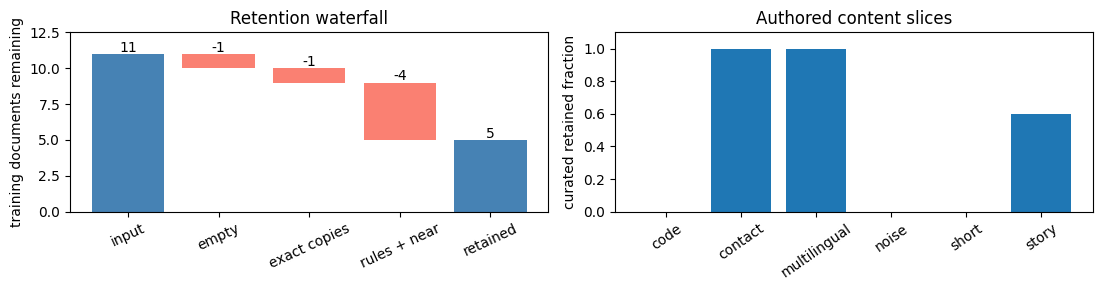

In [3]:
arms = {mode: prepare_corpus(train, mode) for mode in ("raw", "exact", "curated")}
for mode, result in arms.items():
    print(mode, result["counts"], "useful removals:", result["false_removals"])
    assert result["counts"]["input"] == result["counts"]["retained"] + result["counts"]["removed"]
for row in arms["curated"]["ledger"]:
    if not row["accepted"]: print(row["id"], row["slice"], row["reasons"], repr(row["training_text"]))
relaxed = prepare_corpus(train, "curated", min_words=3)
print("Relaxed rule:", relaxed["counts"], relaxed["false_removals"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
counts = [len(train), *[r["counts"]["retained"] for r in arms.values()]]
drops = [counts[i] - counts[i+1] for i in range(3)]
stages = ["input", "empty", "exact copies", "rules + near", "retained"]
axes[0].bar(stages, [counts[0], *drops, counts[-1]],
            bottom=[0, *counts[1:], 0], color=["steelblue", "salmon", "salmon", "salmon", "steelblue"])
for index, label in enumerate([str(counts[0]), *["-" + str(d) for d in drops], str(counts[-1])]):
    axes[0].text(index, [counts[0], *counts[:-1], counts[-1]][index]+.15, label, ha="center")
axes[0].tick_params(axis="x", rotation=25)
axes[0].set(ylabel="training documents remaining", title="Retention waterfall", ylim=(0, 12.5))
slices = sorted({r["slice"] for r in train})
rates = [sum(r["accepted"] for r in arms["curated"]["ledger"] if r["slice"] == s)/sum(r["slice"] == s for r in train) for s in slices]
axes[1].bar(slices, rates); axes[1].tick_params(axis="x", rotation=35)
axes[1].set(ylabel="curated retained fraction", ylim=(0, 1.1), title="Authored content slices")
plt.tight_layout(); plt.show()

### Reference explanation

The pipeline retains 10 raw, 9 exact and 5 curated records. Six removals reconcile with eleven inputs. Useful short text and code are rejected by the fixed rule; the altered garden copy is removed by near-duplicate grouping. These authored usefulness labels expose a tradeoff and are not a general human quality benchmark. In the waterfall, floating red bars show removals from the remaining count; the right plot shows within-slice fractions. A lower threshold changes the eligible distribution; it does not by itself demonstrate better student behavior.

## Prediction — will exact hashing catch an altered garden story?

Predict whether one changed adjective survives exact matching. Compare a permissive LSH configuration with one band containing the whole signature.

## Checkpoint — candidates are not verified duplicates

Use the all-pairs exact oracle on this small fixture. Print missed pairs and false candidates. Then retrieve two original short texts sharing just one trigram and verify why their collision must not become an edge.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

default recall 1.0 precision 1.0 missed [] false candidates []
one band recall 0.3333333333333333 precision 1.0 missed [('t01', 't03'), ('t02', 't03')] false candidates []
many bands recall 1.0 precision 1.0 missed [] false candidates []
Controlled false candidate: [('F', 'G')] [{'pair': ['F', 'G'], 'jaccard': 0.2}] verified [] precision 0.0


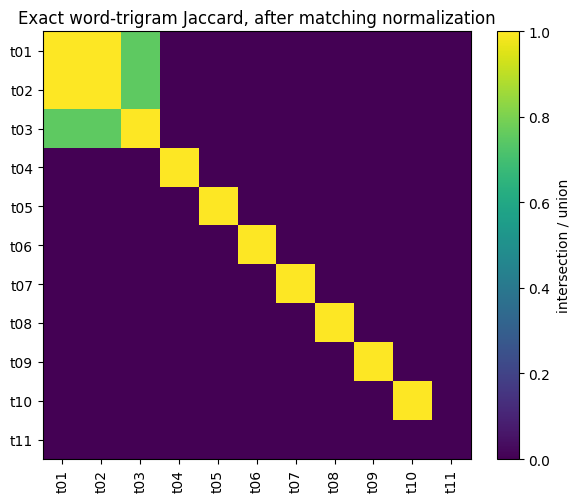

In [4]:
texts = {r["id"]: extract_text(r["html"]) for r in train}
normal = duplicate_audit(texts)
sparse = duplicate_audit(texts, bands=1)
broad = duplicate_audit(texts, bands=64)
for label, audit in [("default", normal), ("one band", sparse), ("many bands", broad)]:
    print(label, "recall", audit["candidate_recall"], "precision", audit["candidate_precision"],
          "missed", audit["missed_edges"], "false candidates", audit["false_candidates"])
collision = duplicate_audit({"F":"red blue green white black", "G":"red blue green orange purple"}, bands=64)
print("Controlled false candidate:", collision["candidates"], collision["similarities"],
      "verified", collision["verified_edges"], "precision", collision["candidate_precision"])
assert collision["false_candidates"] == [("F", "G")] and not collision["verified_edges"]
names = sorted(texts)
matrix = np.diag([jaccard(shingles(texts[name]), shingles(texts[name])) for name in names])
for row in normal["similarities"]:
    a, b = [names.index(i) for i in row["pair"]]; matrix[a,b] = matrix[b,a] = row["jaccard"]
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(names)), names, rotation=90); ax.set_yticks(range(len(names)), names)
ax.set(title="Exact word-trigram Jaccard, after matching normalization")
fig.colorbar(image, ax=ax, label="intersection / union"); plt.tight_layout(); plt.show()

### Reference explanation

The altered copy `t03` is close to `t01/t02` yet not normalized-exact. With one long band, a signature must match in all positions to become a candidate; that loses the altered copy even though the exact oracle detects it. The F/G control shares one of five union trigrams: Jaccard 0.2. One-hash bands retrieve it, but the 0.7 verification rule rejects it; its candidate precision is zero. No F/G text enters the training fixture. Empty texts are excluded from retrieval, and short nonempty texts have a defined fallback shingle. The heatmap reports actual normalized-trigram overlap; it is not semantic similarity.

## Prediction — must every member of a duplicate group be pairwise similar?

Sets A and C share three of five union words. B contains all five. Predict which edges exceed 0.75 and whether all three are grouped.

## Checkpoint — split by ancestry and verified components

Put C in a held-out split to make the leak visible. Restore all three to training and verify the fixture's actual independent held-out sources. Explain why a component is a policy, not a transitive similarity theorem.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

verified edges [('A', 'B'), ('B', 'C')] components [['A', 'B', 'C']]
Planted cross-split issue: [{'kind': 'verified_duplicate', 'ids': ['A', 'B', 'C'], 'splits': ['test', 'train']}]


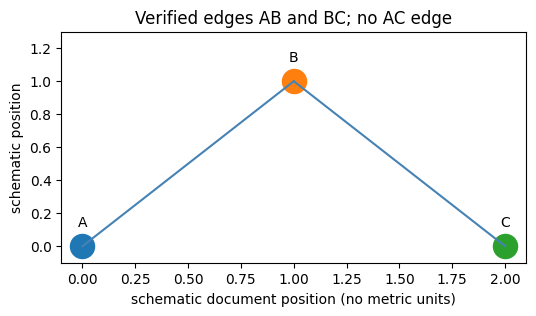

In [5]:
chain = {"A": "red blue green white", "B": "red blue green white black", "C": "red blue green black"}
chain_audit = duplicate_audit(chain, n=1, num_hashes=16, bands=16, threshold=.75)
print("verified edges", chain_audit["verified_edges"], "components", chain_audit["components"])
records = [{"id":k, "source_group":k, "split":"test" if k == "C" else "train"} for k in chain]
print("Planted cross-split issue:", split_audit(records, chain_audit["components"]))
for row in records: row["split"] = "train"
assert not split_audit(records, chain_audit["components"])
fixture_audit = duplicate_audit({r["id"]: extract_text(r["html"]) for r in fixture})
assert not split_audit(fixture, fixture_audit["components"])
positions = {"A": (0, 0), "B": (1, 1), "C": (2, 0)}
fig, ax = plt.subplots(figsize=(6, 3))
for a,b in chain_audit["verified_edges"]:
    ax.plot([positions[a][0], positions[b][0]], [positions[a][1], positions[b][1]], color="steelblue")
for name,(x,y) in positions.items():
    ax.scatter(x,y,s=300); ax.text(x,y+.12,name,ha="center")
ax.set(xlabel="schematic document position (no metric units)", ylabel="schematic position", title="Verified edges AB and BC; no AC edge")
ax.set_ylim(-.1, 1.3)
plt.show()

### Reference explanation

AB and BC each have Jaccard 0.8, while AC has 0.6. Grouping the connected component protects against splitting a source family through an intermediate copy; it does not assert AC passed the threshold. The plot is a graph schematic with verified measured edge values, not a distance embedding. Declared source genealogy is also audited because lexical matching cannot detect every shared origin.

## Prediction — equal shares or equal distinct coverage?

Two sources receive half of 100 supervised-token presentations. One has ten available tokens and one has a thousand. Predict repetitions and whether a two-epoch cap is feasible.

## Checkpoint — bind the units

Show objective shares beside source reuse. Change only rare-source capacity. State why a smaller retained pool can change repetitions even when training presents the same number of targets.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

{'unit': 'supervised tokens', 'sources': {'rare': {'share': 0.5, 'capacity': 10, 'presentations': 50.0, 'effective_epochs': 5.0}, 'large': {'share': 0.5, 'capacity': 1000, 'presentations': 50.0, 'effective_epochs': 0.05}}, 'cap_feasible': False}
Capacity intervention: {'unit': 'supervised tokens', 'sources': {'rare': {'share': 0.5, 'capacity': 50, 'presentations': 50.0, 'effective_epochs': 1.0}, 'large': {'share': 0.5, 'capacity': 1000, 'presentations': 50.0, 'effective_epochs': 0.05}}, 'cap_feasible': True}


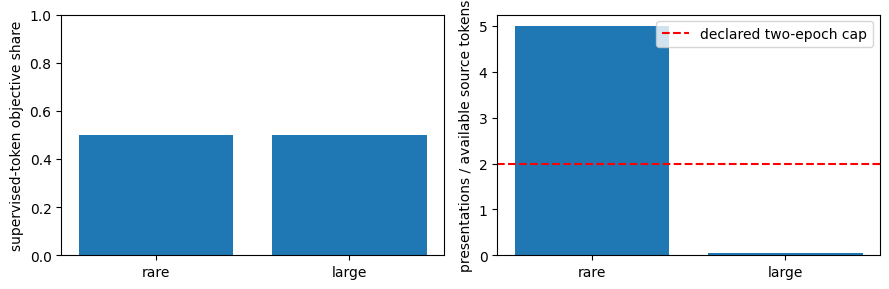

In [6]:
exposure = source_exposure({"rare":.5, "large":.5}, {"rare":10, "large":1000}, 100, epoch_cap=2)
print(exposure)
changed = source_exposure({"rare":.5, "large":.5}, {"rare":50, "large":1000}, 100, epoch_cap=2)
print("Capacity intervention:", changed)
fig, axes = plt.subplots(1,2,figsize=(9,3))
axes[0].bar(list(exposure["sources"]), [r["share"] for r in exposure["sources"].values()]); axes[0].set(ylabel="supervised-token objective share", ylim=(0,1))
axes[1].bar(list(exposure["sources"]), [r["effective_epochs"] for r in exposure["sources"].values()]); axes[1].axhline(2,color="red",linestyle="--",label="declared two-epoch cap")
axes[1].set(ylabel="presentations / available source tokens"); axes[1].legend(); plt.tight_layout(); plt.show()

### Reference explanation

The scarce source repeats five times, versus 0.05 effective epochs for the large source; the cap is infeasible. The correct cap is presentations ≤ cap × capacity in the same token units. Increasing capacity alone changes repetitions while objective shares remain 0.5/0.5. This extends the existing mixture lesson, which already distinguishes example and token shares.

## Prediction — will curated data beat raw data on every slice?

Write a prediction before running all nine bounded fits. Freeze three seeds, the final-checkpoint selection rule, the held-out texts and filter rules. Do not tune rules against the held-out outputs.

## Checkpoint — compare matched updates and targets

Reuse `TrainingSession` for 24 updates per arm, two full 16-target windows per update. Check identical parent hashes within each seed, 768 target presentations per arm and retained omitted-tail counts. Show all seeds, held-out slices and literal capped generations, even if cleaning harms results.

### Reference solution

Run after writing the prediction. This cell executes the named reference and controlled variant.

1701 raw targets 768 NLL 3.625225 tail targets omitted 91 pool epochs 0.787 generation '                                ' EOS False
  slices {'code': 3.8445484161376955, 'multilingual': 3.7299340624328052, 'short': 3.8342060762293197, 'story': 3.409417759288441}
1701 exact targets 768 NLL 3.68166 tail targets omitted 79 pool epochs 0.889 generation '                                ' EOS False
  slices {'code': 3.850070571899414, 'multilingual': 3.736451315223624, 'short': 3.8688516055836395, 'story': 3.5371979106556286}
1701 curated targets 768 NLL 3.712504 tail targets omitted 45 pool epochs 1.171 generation '                                ' EOS False
  slices {'code': 4.069293212890625, 'multilingual': 3.7374376769459574, 'short': 4.12912795122932, 'story': 3.493667151711204}
1702 raw targets 768 NLL 3.723926 tail targets omitted 91 pool epochs 0.787 generation '                                ' EOS False
  slices {'code': 3.8572383880615235, 'multilingual': 3.8305055110826407, 'sho

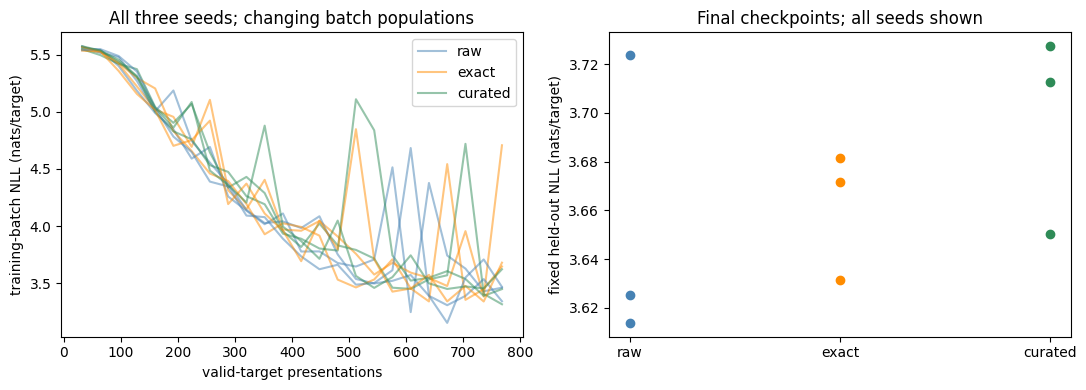

In [7]:
result = learning_reference()
for row in result["arms"]:
    print(row["seed"], row["arm"], "targets", row["target_presentations"],
          "NLL", round(row["held_out_nll_after"], 6), "tail targets omitted", row["omitted_tail_targets"],
          "pool epochs", round(row["effective_pool_epochs"], 3),
          "generation", repr(row["generation"]["text"]), "EOS", row["generation"]["natural_eos"])
    print("  slices", row["held_out_slice_nll"])
assert {r["target_presentations"] for r in result["arms"]} == {768}
for seed in result["seeds"]:
    assert len({r["initial_parameters_sha256"] for r in result["arms"] if r["seed"] == seed}) == 1
fig, axes = plt.subplots(1,2,figsize=(11,4))
colors = {"raw":"steelblue", "exact":"darkorange", "curated":"seagreen"}
for row in result["arms"]:
    axes[0].plot([h["tokens"] for h in row["history"]], [h["loss"] for h in row["history"]], color=colors[row["arm"]], alpha=.5, label=row["arm"] if row["seed"] == result["seeds"][0] else None)
    axes[1].scatter(row["arm"], row["held_out_nll_after"], color=colors[row["arm"]])
axes[0].set(xlabel="valid-target presentations",ylabel="training-batch NLL (nats/target)",title="All three seeds; changing batch populations"); axes[0].legend()
axes[1].set(ylabel="fixed held-out NLL (nats/target)",title="Final checkpoints; all seeds shown")
plt.tight_layout(); plt.show()

### Reference explanation

Every arm sees 768 targets through 24 identical update geometries and schedules, but each training pool contains different documents and repeated exposure. Complete-only windows omit counted tails, including short-document tails; that limitation belongs to the comparison. The observed fixture does not show a universal curated-data benefit, and its greedy continuations can collapse to spaces or repeated letters without EOS. Training NLL curves grade changing batches and should not be used alone to rank arms. The right panel uses common frozen held-out texts; three seeds are too small for a broad method ranking. This cell regenerates actual bounded CPU learning evidence, not model-scale story quality.